# 01 - Dataset Audit and Clinical Verification
### UROP: Improving Cross-Dataset Generalization and Severe-Stage Detection in ROP
This notebook performs **Stage 1 (Dataset Inspection)** and **Stage 2 (Dataset Audit & Class-Distribution Reports)** across all multi-national infant retinal fundus datasets:
1. **ROP-VL** (China, 2,020 images, 1,116 infants)
2. **Ostrava** (Czech Republic, 6,004 images, 188 infants, 3 camera systems)
3. **FARFUM-RoP** (Iran, 1,533 images, 68 infants, Plus-disease grading)
4. **HVDROPDB** (India, 185 classification test benchmark images)
5. **Shenzhen** (China, 1,099 images - audited and documented as excluded due to ROP-VL overlap)


In [4]:
# Environment Setup (Supports Google Colab and Local Windows/Linux)
import os, sys
from pathlib import Path

# Detect Google Colab and mount Drive
if "COLAB_GPU" in os.environ or os.path.exists("/content"):
    from google.colab import drive
    drive.mount("/content/drive")
    sys.path.append("/content/drive/MyDrive/ROP_UROP")
    sys.path.append("/content/ROP_UROP")
else:
    sys.path.append(r"d:/UROP")

import torch
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))


PyTorch Version: 2.10.0+cpu
CUDA Available: False


In [5]:
# Run Dataset Auditor across all 5 sources
from src.audit import DatasetAuditor

auditor = DatasetAuditor()
auditor.audit_ropvl()
auditor.audit_ostrava()
auditor.audit_farfum()
auditor.audit_hvdropdb()
auditor.audit_shenzhen()
auditor.generate_reports()
auditor.generate_visualizations()



AUDITING DATASET: ROP-VL (China)
  Total Images: 2020 | Unique Patients: 1116
  Normal: 623 (381 pts) | Active ROP: 1052
  Severe Cases (Stage 4/5 + A-ROP): 237 images across 158 patients

AUDITING DATASET: Ostrava (Czech Republic)
  Total Images: 6004 | Unique Patients: 188 across 484 exams
  Normal: 2980 (135 pts) | Active ROP (Stages 1-3, AP-ROP): 1305 (18 pts)
  Excluded (ROP 0, st.p. ROP, non-ROP pathologies): 1719 images
  Camera Systems: Clarity RetCam 3: 2578 imgs (81 pts), Phoenix ICON: 2452 imgs (61 pts), Natus RetCam Envision: 974 imgs (46 pts)

AUDITING DATASET: FARFUM-RoP (Iran)
  Total Images: 1533 | Unique Patients: 68
  Plus Disease Consensus: Normal: 782 | Pre-Plus: 479 | Plus: 272
  Role: Strictly reserved for Plus-disease experiments (Not pooled into Task A)

AUDITING DATASET: HVDROPDB (India)
  Total Images: 185 | Normal: 100 | ROP: 85
  Role: External zero-shot test set (fold = -1)
  Duplicate Warning: Neo_ROP contains near-identical burst frames (35 imgs -> 15 cl

In [8]:
# Display Summary Audit Report
import pandas as pd
from IPython.display import display

summary_df = pd.read_csv(r"d:/UROP/reports\dataset_audit_report.csv" if os.path.exists(r"d:/UROP") else "reports/dataset_audit_report.csv")
display(summary_df)


,dataset_name,country_source,hospital,total_images,unique_patients,normal_images,normal_patients,active_rop_images,laser_treated_images,severe_images,...,stage4_images,stage5_images,arop_images,camera_devices,missing_annotations,missing_images,duplicate_images,corrupted_images,sample_dimensions,status
0,ROP-VL,China,Guangdong Women & Children Hospital,2020,1116,623,381,1052,345,237,...,59,30,148.0,"3 camera models (grouped by resolution <900, 9...",0,0,0,0,"{(1454, 1454): 6, (1462, 1462): 3, (1464, 1464...",NaN
1,Ostrava,Czech Republic,University Hospital Ostrava,6004,188,2980,135,1305,379,470,...,0,0,470.0,"Clarity RetCam 3: 2578 imgs (81 pts), Phoenix ...",0,0,0,0,"RetCam3: 1240x1240, Phoenix: 640x480, Envision...",NaN
2,FARFUM-RoP,Iran,"Farabi Eye Hospital, Tehran",1533,68,782,35,751,0,272,...,N/A (Plus-disease grading),N/A (Plus-disease grading),NaN,Clarity RetCam 3,0,0,0,0,1600x1200 (all images),NaN
3,HVDROPDB,India,Aravind Eye Hospital / HVROP,185,Not provided (Benchmark Test Only),100,NaN,85,0,Not graded (Binary ROP),...,NaN,NaN,NaN,"Forus 3nethra neo (2040x2040), Clarity RetCam ...",0,0,35 Neo_ROP images collapse to 15 unique cluste...,0,"Neo: 2040x2040, RetCam: 640x480",NaN
4,Shenzhen 2024,China,Shenzhen Eye Hospital,1099,483,236,Overlaps ROP-VL,520,343,Excluded,...,0,0,0.0,512x512 cropped fundus,0,0,"1,036 / 1,099 images match ROP-VL (pHash dist ...",0,512x512,EXCLUDED FROM PRIMARY EXPERIMENTS (Per Section...


In [10]:
# Display Granular Per-Class Diagnostic Breakdown
classes_df = pd.read_csv(r"d:/UROP/reports\per_class_breakdown.csv" if os.path.exists(r"d:/UROP") else "reports/per_class_breakdown.csv")
display(classes_df)


,dataset,country,category,task_role,severity_group,images,patients
0,ROP-VL,China,normal,Normal,NaN,623,381
1,ROP-VL,China,Laser-treated ROP,Laser-Treated (Excluded),NaN,345,224
2,ROP-VL,China,Stage 2 ROP,Active ROP,mild,338,253
3,ROP-VL,China,Stage 3 ROP,Active ROP,moderate,241,174
4,ROP-VL,China,Stage 1 ROP,Active ROP,mild,236,180
5,ROP-VL,China,A-ROP,Active ROP,severe,148,103
6,ROP-VL,China,Stage 4 ROP,Active ROP,severe,59,46
7,ROP-VL,China,Stage 5 ROP,Active ROP,severe,30,27
8,Ostrava,Czech Republic,DG 0: physiological (Normal),Normal,NaN,2980,135
9,Ostrava,Czech Republic,DG 1: ROP 0 (Ambiguous),Excluded,NaN,45,4


Task A Screening Cohort Distribution:


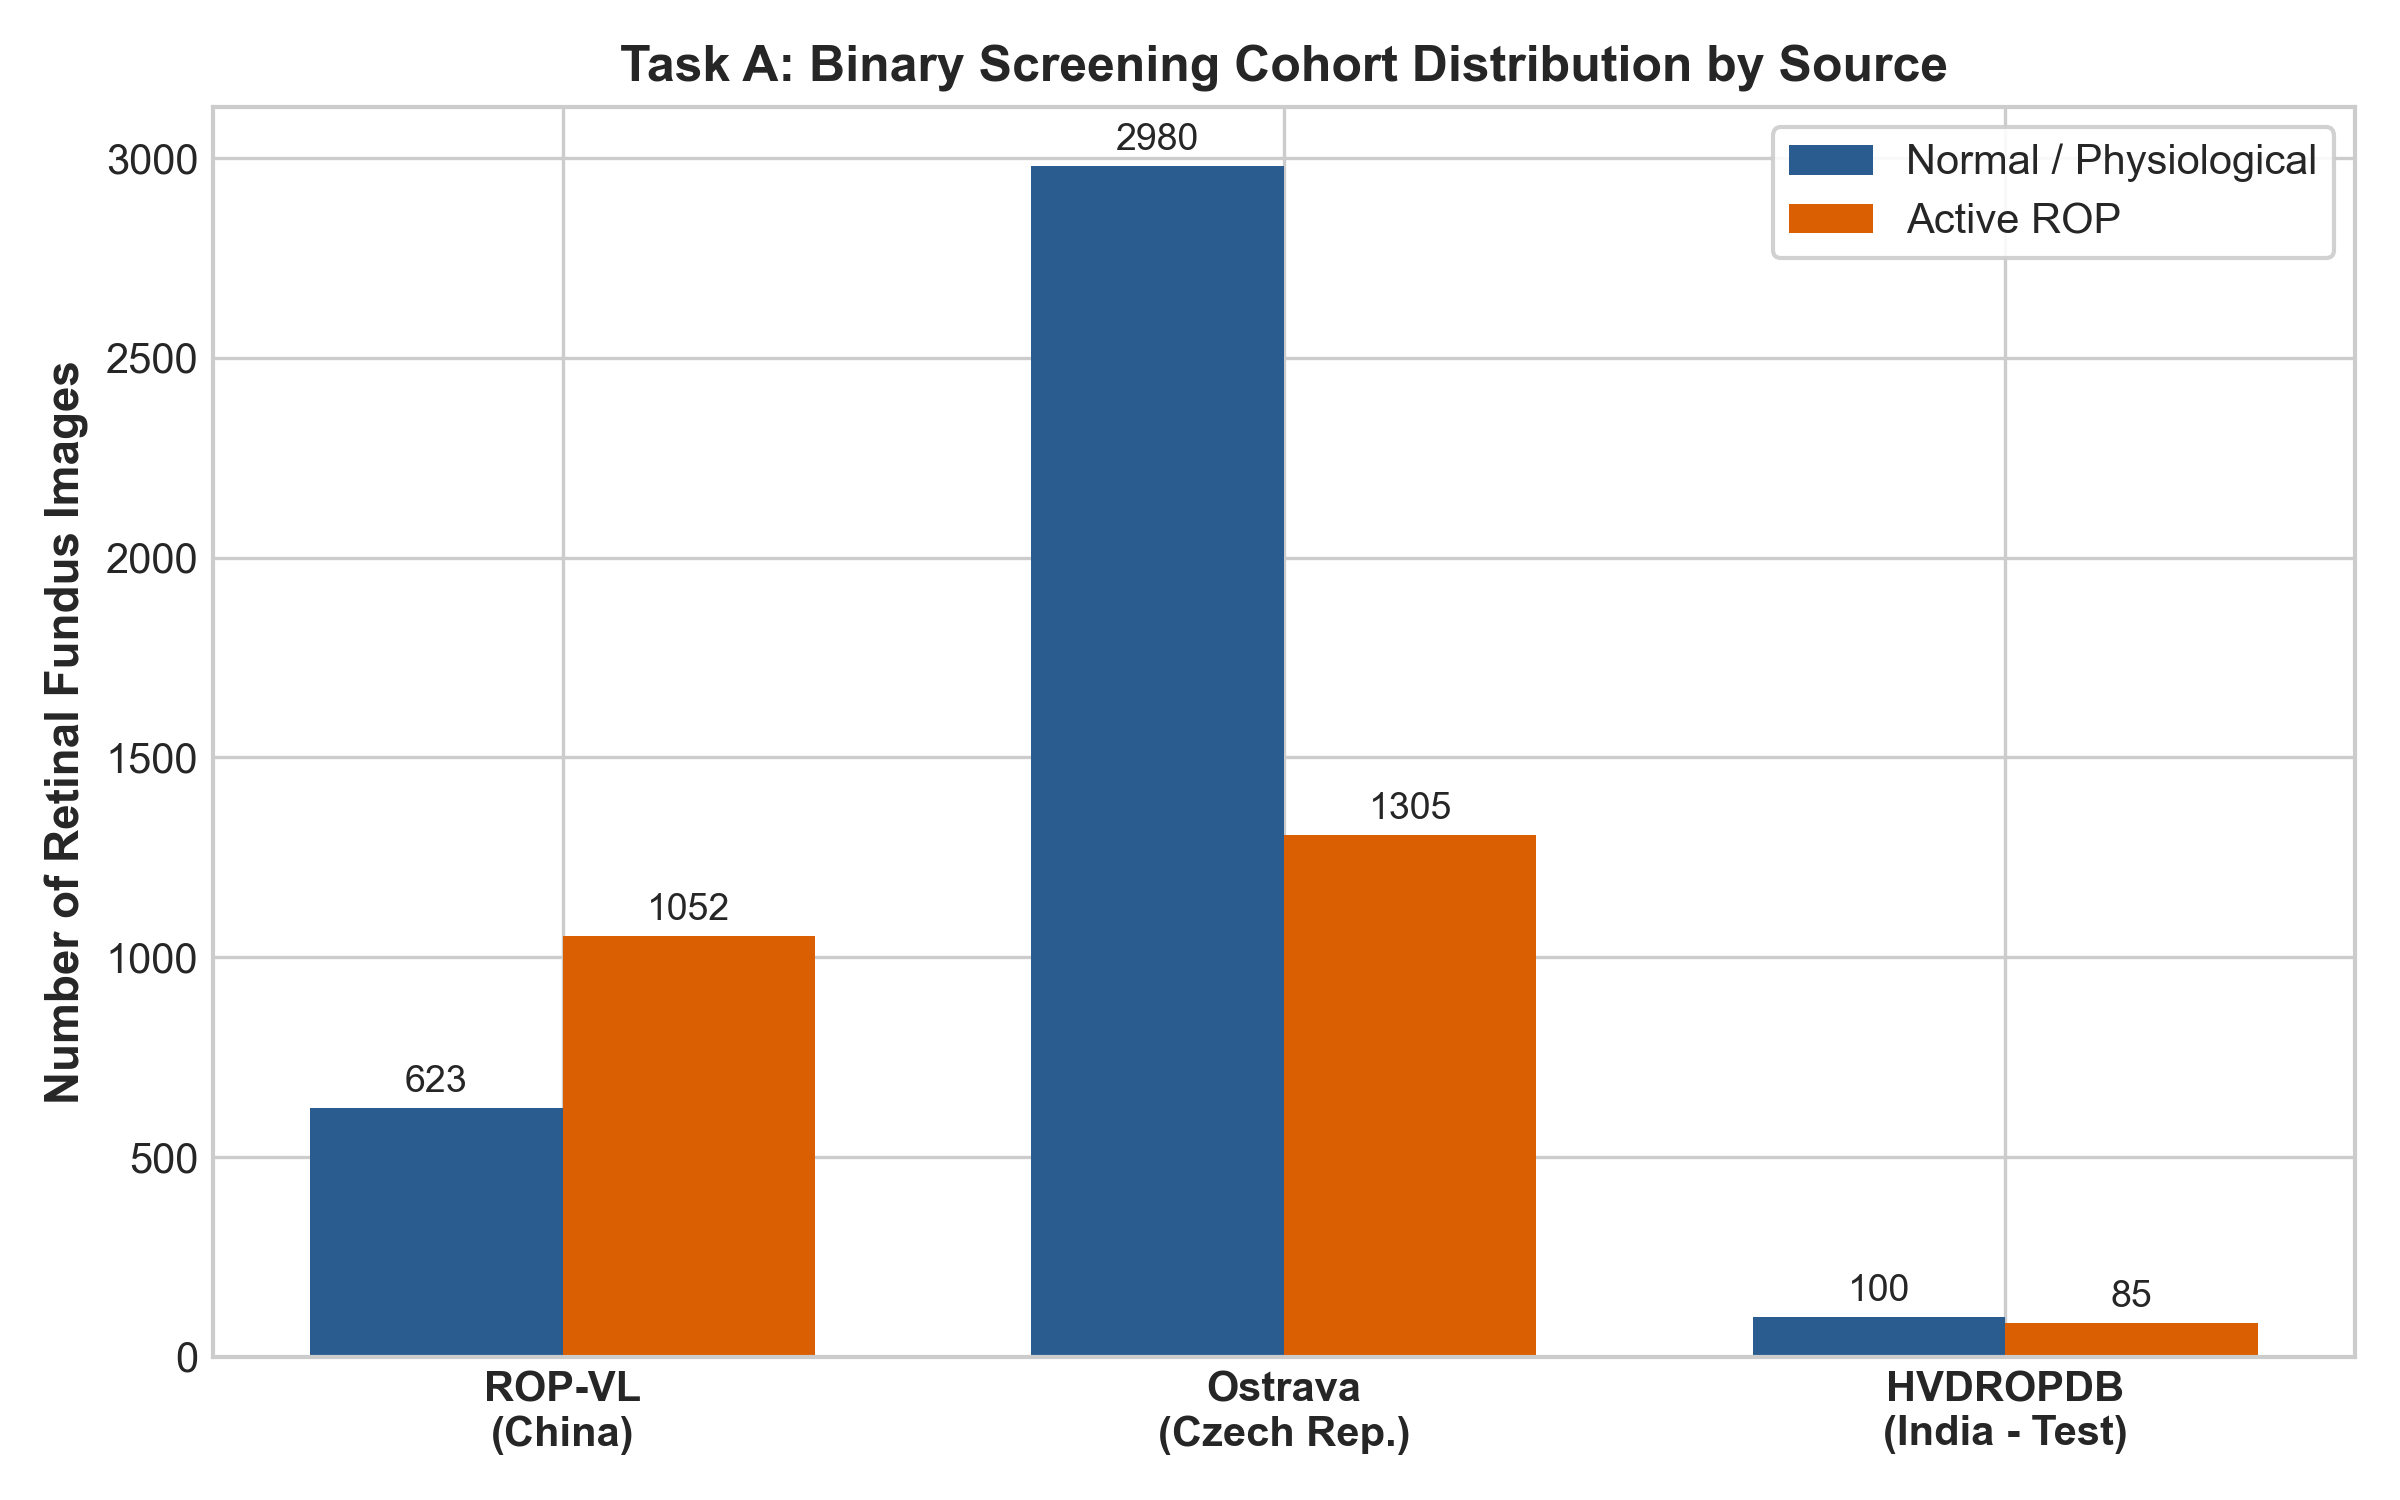

Task B Severe-Stage Imbalance Distribution:


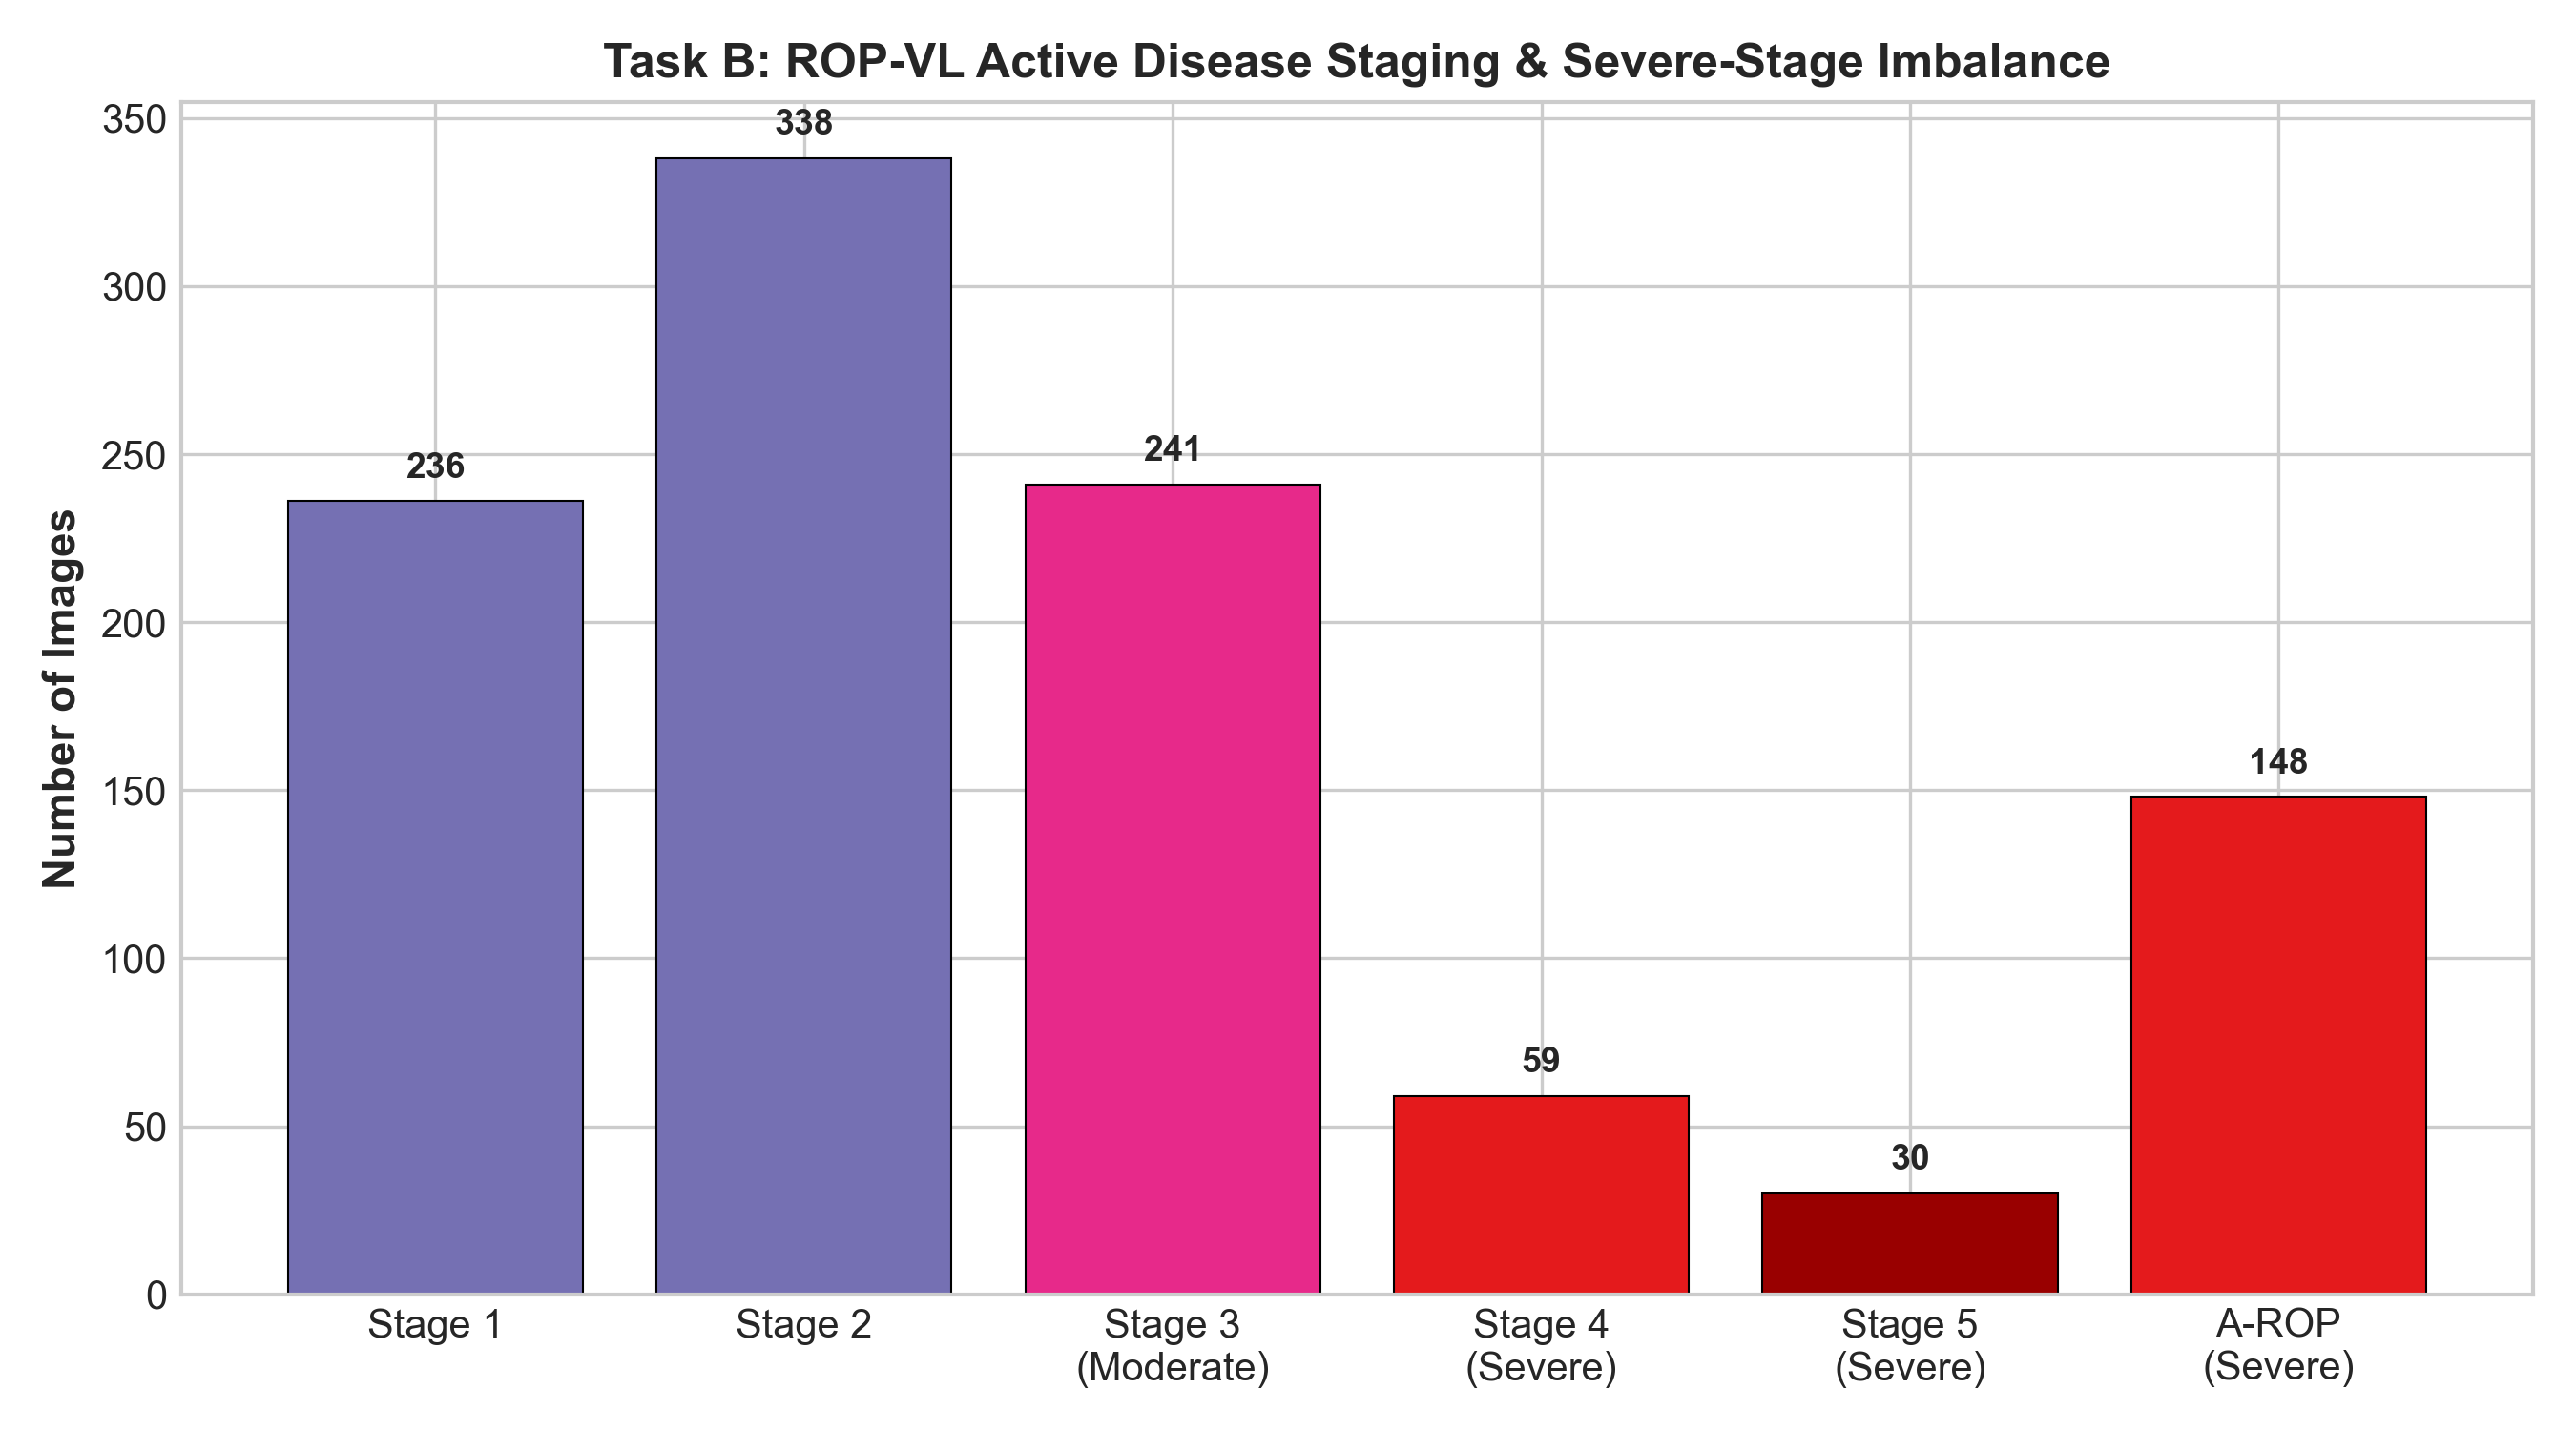

In [12]:
# Display Generated Visualizations
from IPython.display import Image, display

fig_dir = Path("D:/UROP/figures") if Path("D:/UROP").exists() else Path("figures")
print("Task A Screening Cohort Distribution:")
display(Image(filename=str(fig_dir / "class_distribution_by_source.png")))

print("Task B Severe-Stage Imbalance Distribution:")
display(Image(filename=str(fig_dir / "severe_stage_distribution.png")))
